# 01. Sensor and noise

A sensor counts photons, and counting is noisy. This notebook follows the signal along the block diagram of L2 s34: photons become electrons, noise gets added at several places, the ADC turns charge into digital numbers. You will measure shot noise, check the SNR formula of L2 s31-33 against the simulator in `isp.sensor`, compare exposure time against ISO, and average frames to beat noise (L2 s40-43). The theory is in `docs/01_sensor_and_noise.md`.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import isp` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import isp
from isp import utils, scenes
srgb = utils.linear_to_srgb      # linear light -> display values for imshow


def show_row(images, titles, figsize=(12, 4), cmap=None, vmin=None, vmax=None):
    # one row of image panels, axes off
    fig, axs = plt.subplots(1, len(images), figsize=figsize)
    for ax, im, t in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(np.clip(im, 0, 1) if (vmin is None and im.ndim == 3) else im,
                  cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(t, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

from dataclasses import replace
from isp import sensor, cfa

P = sensor.PRESETS
print({k: (v.name, v.bits, v.full_well, v.read_noise) for k, v in P.items()})

{'retiga_4000r': ('Retiga 4000R', 12, 40000, 12.0), 'aptina_mt9p031': ('Aptina MT9P031', 12, 8500, 2.6), 'dslr': ('DSLR', 14, 30000, 5.0), 'phone': ('Phone', 10, 5000, 2.5)}


## From photons to digital numbers (L2 s34)

`expose` is the left half of the diagram (photons, QE, dark current, Poisson noise, full-well clipping). `adc` is the right half (read noise, gain, black level, rounding). Below, the astronaut goes through both, one step at a time, as a single-plane RAW mosaic.

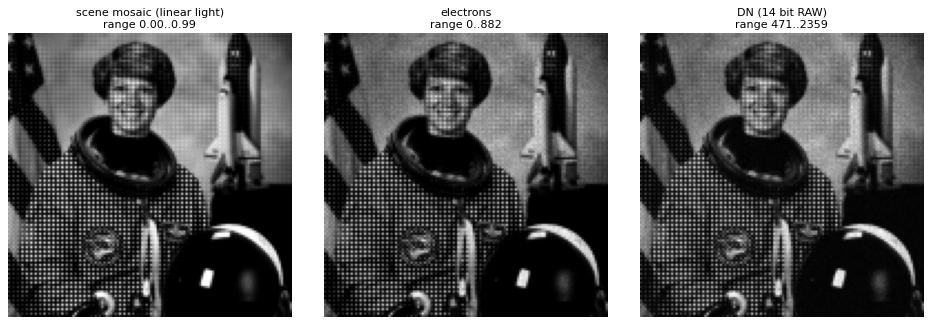

full well 30000 e-  | white level 16383.0 DN | black level 512 DN
scene white gives 800.0 e- (flux 1e5 photons/px/s x QE 0.4 x 0.02 s)


In [2]:
scene = scenes.load('astronaut', 128)
mos = cfa.mosaic(scene)                          # what the CFA lets through (H, W)
par = P['dslr']
e = sensor.expose(mos, exposure=0.02, params=par, seed=0)             # electrons
dn = sensor.adc(e, par, iso=400, seed=1)                              # digital numbers
lin = sensor.normalize(dn, dict(black_level=par.black_level, white_level=par.white_level))

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, a, t in zip(axs, [mos, e, dn], ['scene mosaic (linear light)', 'electrons', 'DN (14 bit RAW)']):
    ax.imshow(a, cmap='gray'); ax.set_title(f'{t}\nrange {a.min():.0f}..{a.max():.0f}' if a.max() > 2 else f'{t}\nrange {a.min():.2f}..{a.max():.2f}', fontsize=10)
    ax.axis('off')
plt.tight_layout(); plt.show()
print('full well', par.full_well, 'e-  | white level', par.white_level, 'DN | black level', par.black_level, 'DN')
print('scene white gives', 0.4 * 1e5 * 0.02, 'e- (flux 1e5 photons/px/s x QE 0.4 x 0.02 s)')

The three panels look alike but the numbers underneath change units: unit-less light, then electrons, then integer DN with an offset (the black level). Nothing reaches the full well here, so the picture is dark; ISO is the knob that makes it bright again without adding any light.

## Shot noise: $\sigma = \sqrt{\lambda}$

Photons arrive randomly, so the electron count is Poisson distributed with variance equal to its mean. Here a perfect sensor (no read noise, no dark current) looks at flat fields of increasing brightness.

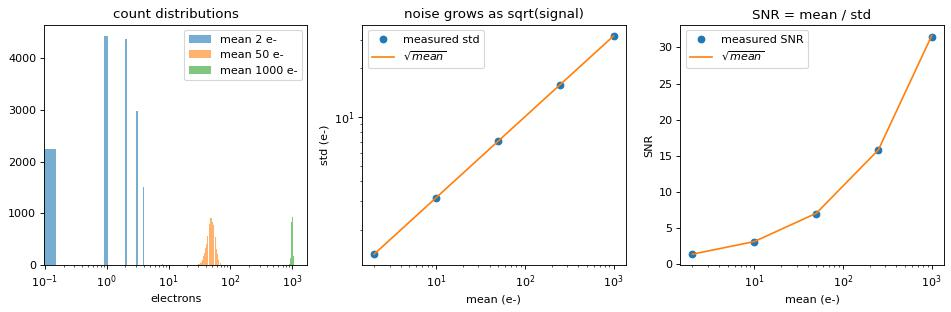

mean (e-): [   2.    10.    50.   250.2 1000. ]
std  (e-): [ 1.42  3.15  7.14 15.82 31.79]  sqrt(mean): [ 1.41  3.16  7.07 15.82 31.62]


In [3]:
ideal = sensor.clean_params(P['dslr'], dark_current=0.0, read_noise=0.0)

def shot_noise_demo(values=(0.002, 0.01, 0.05, 0.25, 1.0), exposure=0.025, plot=True):
    means, stds = [], []
    for k, v in enumerate(values):
        e = sensor.expose(np.full((128, 128), v), exposure, ideal, seed=k)
        means.append(e.mean()); stds.append(e.std())
    means, stds = np.array(means), np.array(stds)
    if plot:
        fig, axs = plt.subplots(1, 3, figsize=(12, 4))
        for k in (0, 2, 4):
            e = sensor.expose(np.full((128, 128), values[k]), exposure, ideal, seed=k)
            axs[0].hist(e.ravel(), bins=60, alpha=0.6, label=f'mean {e.mean():.0f} e-')
        axs[0].set_xscale('log'); axs[0].set_xlabel('electrons'); axs[0].legend(); axs[0].set_title('count distributions')
        axs[1].loglog(means, stds, 'o', label='measured std')
        axs[1].loglog(means, np.sqrt(means), '-', label=r'$\sqrt{mean}$')
        axs[1].set_xlabel('mean (e-)'); axs[1].set_ylabel('std (e-)'); axs[1].legend(); axs[1].set_title('noise grows as sqrt(signal)')
        axs[2].semilogx(means, means / stds, 'o', label='measured SNR')
        axs[2].semilogx(means, np.sqrt(means), '-', label=r'$\sqrt{mean}$')
        axs[2].set_xlabel('mean (e-)'); axs[2].set_ylabel('SNR'); axs[2].legend(); axs[2].set_title('SNR = mean / std')
        plt.tight_layout(); plt.show()
    return means, stds

means, stds = shot_noise_demo()
print('mean (e-):', np.round(means, 1))
print('std  (e-):', np.round(stds, 2), ' sqrt(mean):', np.round(np.sqrt(means), 2))

The measured standard deviation follows $\sqrt{\text{mean}}$ over the whole range. Brighter pixels have more absolute noise but a better SNR, which is why shadows are always the noisy part of a photo.

## The SNR formula and the slide examples (L2 s31-33)

With shot noise, dark current $D$ and read noise $N_r$ adding in variance, $\mathrm{SNR}=\dfrac{P Q_e t}{\sqrt{P Q_e t + D t + N_r^2}}$. The dynamic range is the same idea for the largest signal against the noise in the dark. The two sensors on the slides are the `retiga_4000r` and `aptina_mt9p031` presets.

SNR  Retiga 4000R: 20.85:1   (slide: 20.8:1)
SNR  Aptina MT9P031: 6.45:1   (slide: 6.5:1)
DR   Retiga  t= 1.000 s:   3314:1 = 11.7 bits
DR   Retiga  t= 0.017 s:   3333:1 = 11.7 bits
DR   Aptina  t= 1.000 s:   1504:1 = 10.6 bits
DR   Aptina  t= 0.017 s:   3173:1 = 11.6 bits


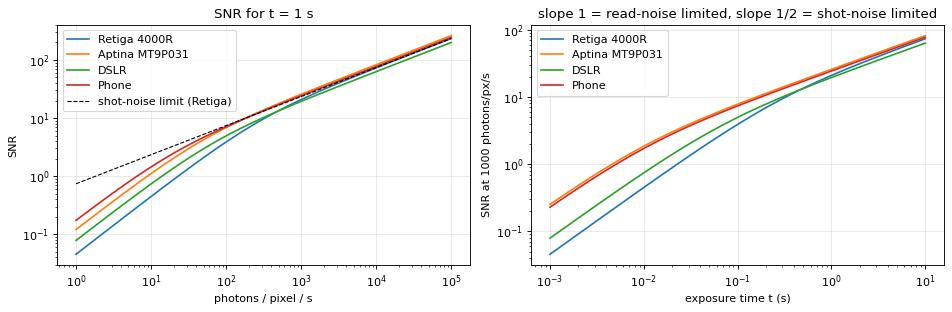

In [4]:
R, A = P['retiga_4000r'], P['aptina_mt9p031']
snr_retiga = sensor.snr_theory(1000, R.qe, 1.0, R.dark_current, R.read_noise)
snr_aptina = sensor.snr_theory(1000 / 11, A.qe, 1.0, A.dark_current, A.read_noise)   # pixels 1/11 the area
print(f'SNR  Retiga 4000R: {snr_retiga:.2f}:1   (slide: 20.8:1)')
print(f'SNR  Aptina MT9P031: {snr_aptina:.2f}:1   (slide: 6.5:1)')
for name, p in (('Retiga', R), ('Aptina', A)):
    for t in (1.0, 1 / 60):
        dr = sensor.dynamic_range(p.full_well, p.dark_current, t, p.read_noise)
        print(f'DR   {name:7s} t={t:6.3f} s: {dr:6.0f}:1 = {np.log2(dr):.1f} bits')

def snr_curves(params_list, t=1.0, plot=True):
    # SNR against photon flux for several sensors
    P_ = np.logspace(0, 5, 200)
    curves = {p.name: sensor.snr_theory(P_, p.qe, t, p.dark_current, p.read_noise) for p in params_list}
    if plot:
        fig, axs = plt.subplots(1, 2, figsize=(12, 4))
        for name, c in curves.items():
            axs[0].loglog(P_, c, label=name)
        axs[0].loglog(P_, np.sqrt(P_ * R.qe * t), 'k--', lw=1, label='shot-noise limit (Retiga)')
        axs[0].set_xlabel('photons / pixel / s'); axs[0].set_ylabel('SNR'); axs[0].legend(); axs[0].grid(alpha=.3)
        axs[0].set_title(f'SNR for t = {t:g} s')
        ts = np.logspace(-3, 1, 100)
        for p in params_list:
            axs[1].loglog(ts, sensor.snr_theory(1000, p.qe, ts, p.dark_current, p.read_noise), label=p.name)
        axs[1].set_xlabel('exposure time t (s)'); axs[1].set_ylabel('SNR at 1000 photons/px/s'); axs[1].legend(); axs[1].grid(alpha=.3)
        axs[1].set_title('slope 1 = read-noise limited, slope 1/2 = shot-noise limited')
        plt.tight_layout(); plt.show()
    return curves

_ = snr_curves([R, A, P['dslr'], P['phone']])

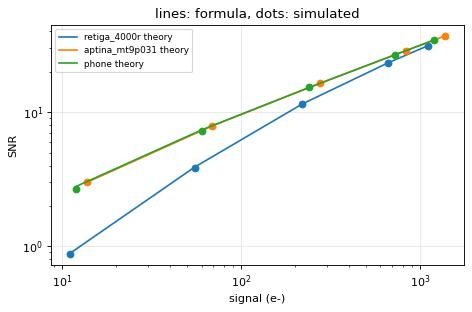

retiga_4000r max relative deviation: 1.5 %
aptina_mt9p031 max relative deviation: 0.4 %
phone max relative deviation: 5.1 %


In [5]:
def check_snr(names=('retiga_4000r', 'aptina_mt9p031', 'phone'), values=(0.01, 0.05, 0.2, 0.6, 1.0), exposure=0.02, plot=True):
    # simulated flat-field SNR (temporal std over 24 captures) against the formula
    rows = {}
    for nm in names:
        p = P[nm]
        th = [float(sensor.snr_theory_params(v, exposure, p)) for v in values]
        me = [sensor.measure_snr(p, value=v, exposure=exposure, iso=100, n=24, shape=(24, 24))['snr'] for v in values]
        rows[nm] = (th, me)
    if plot:
        plt.figure(figsize=(6, 4))
        for nm, (th, me) in rows.items():
            l, = plt.loglog(np.array(values) * 1e5 * P[nm].qe * exposure, th, '-', label=f'{nm} theory')
            plt.loglog(np.array(values) * 1e5 * P[nm].qe * exposure, me, 'o', color=l.get_color())
        plt.xlabel('signal (e-)'); plt.ylabel('SNR'); plt.legend(fontsize=8); plt.grid(alpha=.3)
        plt.title('lines: formula, dots: simulated'); plt.tight_layout(); plt.show()
    return rows

rows = check_snr()
for nm, (th, me) in rows.items():
    print(nm, 'max relative deviation: %.1f %%' % (100 * np.max(np.abs(np.array(me) / np.array(th) - 1))))

Our numbers match the slides. In the left plot the curves bend from a slope of 1 (read noise dominates, every doubling of light doubles the SNR) to a slope of 1/2 (shot noise dominates); the Aptina's high dark current hurts it at long exposures, which is the point of slide 33. In the second figure the simulated dots (`measure_snr`, temporal std of a flat field) sit on the formula, up to a few percent of scatter from using only 24 frames.

## A gallery of noise types (L2 s18-30)

Each panel switches on one noise source of the model, with the others off. Noise panels are stretched to their own mean $\pm 4\sigma$; the number in the title is the standard deviation in DN. For the two fixed-pattern sources the mean of 16 shots is shown, so the random part averages out and only what the sensor repeats every time is left.

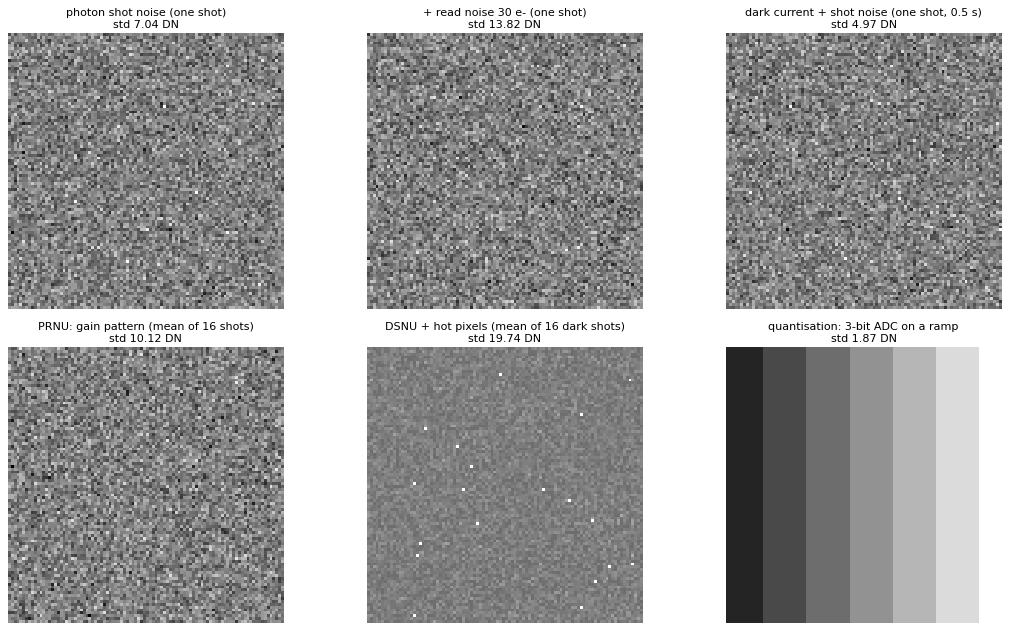

In [6]:
def noise_gallery(plot=True):
    base = replace(P['dslr'], bits=12, black_level=64, full_well=10000, qe=0.5, dark_current=0.0, read_noise=0.0,
                   prnu=0.0, dsnu=0.0, hot_pixel_fraction=0.0, hot_pixel_rate=0.0)
    fixed = replace(base, dark_current=50.0, dsnu=40.0, hot_pixel_fraction=2e-3, hot_pixel_rate=2000.0, prnu=0.03)
    quiet = replace(base, full_well=1e7, bits=3, black_level=0, qe=1.0)          # so much light that shot noise vanishes
    ramp = np.tile(np.linspace(0.1, 1.0, 96), (96, 1))
    flat = lambda v: np.full((96, 96), v)

    def avg(img, p, t, n=16):                    # n shots averaged: temporal noise shrinks, fixed pattern stays
        return np.mean([sensor.capture(img, t, 100, p, seed=10 + k)[0] for k in range(n)], axis=0)

    cases = [
        ('photon shot noise (one shot)', sensor.capture(flat(0.3), 0.02, 100, base, seed=3)[0]),
        ('+ read noise 30 e- (one shot)', sensor.capture(flat(0.3), 0.02, 100, replace(base, read_noise=30.0), seed=3)[0]),
        ('dark current + shot noise (one shot, 0.5 s)', sensor.capture(flat(0.0), 0.5, 100, replace(base, dark_current=300.0), seed=3)[0]),
        ('PRNU: gain pattern (mean of 16 shots)', avg(flat(0.8), replace(base, prnu=0.03), 0.02)),
        ('DSNU + hot pixels (mean of 16 dark shots)', avg(flat(0.0), fixed, 0.5)),
        ('quantisation: 3-bit ADC on a ramp', sensor.capture(ramp, 0.1, 100, quiet, flux_at_white=1e8, seed=3)[0]),
    ]
    out = []
    fig, axs = plt.subplots(2, 3, figsize=(14, 8))
    for ax, (name, dn) in zip(axs.ravel(), cases):
        m, s = dn.mean(), dn.std()
        if 'ramp' in name:
            ax.imshow(dn, cmap='gray', vmin=0, vmax=7, interpolation='nearest')
        else:
            ax.imshow(dn, cmap='gray', vmin=m - 4 * s, vmax=m + 4 * s, interpolation='nearest')
        ax.set_title(f'{name}\nstd {s:.2f} DN', fontsize=10); ax.axis('off')
        out.append((name, s))
    plt.tight_layout(); plt.show()
    return out

_ = noise_gallery()

Shot and read noise are temporal: a new shot gives a new pattern. PRNU, DSNU and hot pixels are fixed in the sensor, so they come back identically every frame, which is why they can be calibrated away (see the dark-frame section below). Quantisation noise only matters when the ADC steps are comparable to the other noise.

## Exposure time against ISO at equal brightness (L2 s36-39)

Brightness is $\propto$ light $\times$ ISO, so a long exposure at low ISO and a short exposure at high ISO give the same picture brightness. They do not give the same noise: the short one collected fewer electrons.

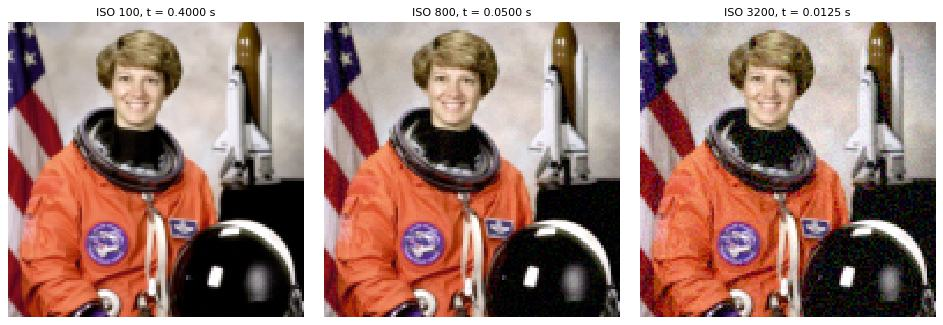

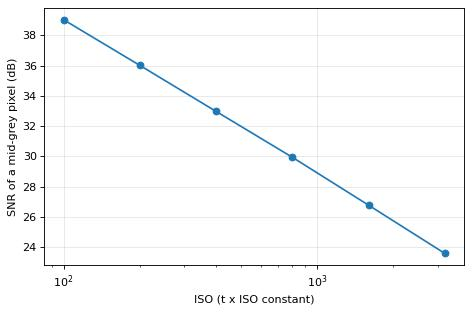

electrons at mid-grey: [7998 3999 2000 1000  500  250]


In [7]:
def iso_vs_exposure(isos=(100, 200, 400, 800, 1600, 3200), product=40.0, plot=True):
    # t * ISO = product (so ISO 100 -> 0.4 s)
    p = P['dslr']
    sc = scenes.load('astronaut', 128)
    imgs, snrs, mean_e = [], [], []
    for iso in isos:
        t = product / iso
        dn, meta = sensor.capture(sc, t, iso, p, seed=5)
        imgs.append(srgb(sensor.normalize(dn, meta) * 2.0))        # x2 so the picture is not too dark
        r = sensor.measure_snr(p, value=0.5, exposure=t, iso=iso, n=16, shape=(24, 24))
        snrs.append(r['snr']); mean_e.append(r['mean_e'])
    if plot:
        pick = [0, 3, 5]
        show_row([imgs[k] for k in pick], [f'ISO {isos[k]}, t = {product / isos[k]:.4f} s' for k in pick])
        plt.figure(figsize=(6, 4))
        plt.semilogx(isos, 20 * np.log10(snrs), 'o-')
        plt.xlabel('ISO (t x ISO constant)'); plt.ylabel('SNR of a mid-grey pixel (dB)'); plt.grid(alpha=.3)
        plt.tight_layout(); plt.show()
    return dict(isos=isos, snr=snrs, electrons=mean_e)

r = iso_vs_exposure()
print('electrons at mid-grey:', np.round(r['electrons']).astype(int))

The three pictures have the same brightness, but the high-ISO one is visibly grainier, and the curve drops with every doubling of ISO because the number of electrons halves. This is the rule of L2 s39: use the longest exposure that motion and saturation allow, and raise ISO last.

## Averaging frames (L2 s40-43)

If the noise of each frame is independent, the mean of $M$ frames has $\sigma/\sqrt{M}$. A tripod and many short exposures are the camera version of this.

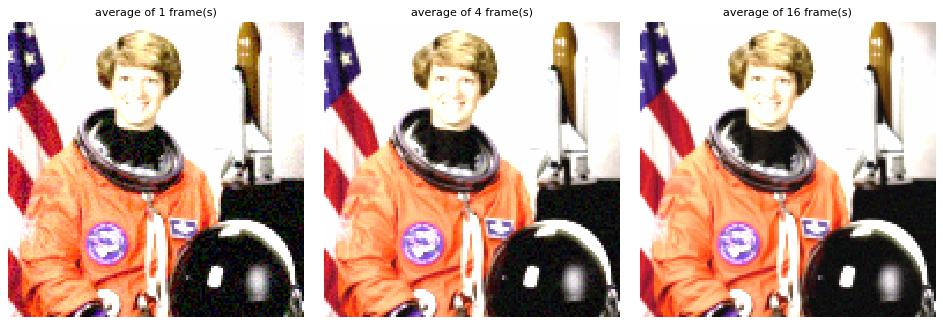

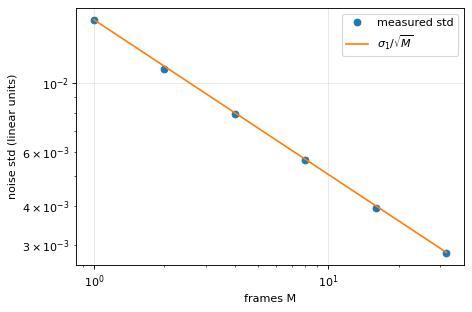

std(1) / std(M): [1.   1.44 2.03 2.84 4.08 5.7 ]  sqrt(M): [1.   1.41 2.   2.83 4.   5.66]


In [8]:
def averaging_demo(Ms=(1, 2, 4, 8, 16, 32), plot=True):
    p = sensor.clean_params(P['phone'])
    flat = np.full((64, 64), 0.15)
    frames_flat = [sensor.normalize(sensor.capture(flat, 0.01, 800, p, seed=k)[0],
                                    dict(black_level=p.black_level, white_level=p.white_level), clip=False) for k in range(max(Ms))]
    stds = [sensor.average_frames(frames_flat[:M]).std() for M in Ms]
    sc = scenes.load('astronaut', 128)
    frames = [sensor.normalize(sensor.capture(sc, 0.01, 800, p, seed=k)[0],
                               dict(black_level=p.black_level, white_level=p.white_level)) for k in range(16)]
    if plot:
        pick = (1, 4, 16)
        show_row([srgb(sensor.average_frames(frames[:M]) * 3) for M in pick], [f'average of {M} frame(s)' for M in pick])
        plt.figure(figsize=(6, 4))
        plt.loglog(Ms, stds, 'o', label='measured std')
        plt.loglog(Ms, stds[0] / np.sqrt(Ms), '-', label=r'$\sigma_1 / \sqrt{M}$')
        plt.xlabel('frames M'); plt.ylabel('noise std (linear units)'); plt.legend(); plt.grid(alpha=.3)
        plt.tight_layout(); plt.show()
    return dict(Ms=Ms, stds=stds)

res = averaging_demo()
print('std(1) / std(M):', np.round(res['stds'][0] / np.array(res['stds']), 2), ' sqrt(M):', np.round(np.sqrt(res['Ms']), 2))

The ratio of the noise of one frame to the noise of the average tracks $\sqrt{M}$, so 16 frames buy a factor 4. The cost is time, and the scene has to hold still, which is the trade-off that makes burst photography on phones work for static scenes only.

## Dark frames and hot pixels (L2 s24-30)

Dark current, DSNU and hot pixels are the same every shot, so a picture taken with the lens cap on measures them. Averaging a few dark frames (a *master dark*) removes most of the random noise from that measurement; subtracting it removes the fixed pattern from a real shot.

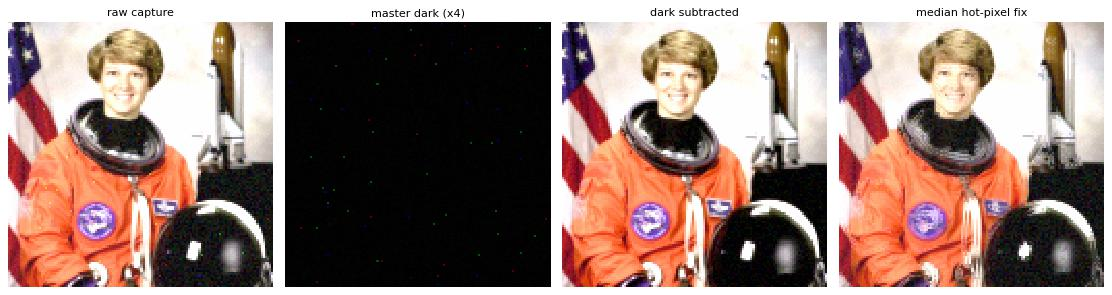

true hot pixels: 71 | mean excess over the 3x3 median at those pixels (linear units): {'raw': 0.078, 'subtracted': 0.001, 'median': 0.009}


In [9]:
def dark_frame_demo(plot=True):
    from scipy.ndimage import median_filter
    p = replace(P['phone'], bits=12, black_level=64, dark_current=20.0, dsnu=15.0, hot_pixel_fraction=1.5e-3, hot_pixel_rate=800.0)
    sc = scenes.load('astronaut', 128) * 0.08
    t, iso = 0.5, 100
    dn, meta = sensor.capture(sc, t, iso, p, seed=2)
    dark = sensor.master_dark(sc.shape, t, iso, p, n=16)
    fixed = sensor.subtract_dark(dn, dark, p.black_level)
    raw, sub = sensor.normalize(dn, meta), sensor.normalize(fixed, meta)
    med = sensor.fix_hot_pixels(raw, threshold=0.03)
    hot = sensor.fixed_pattern(sc.shape, p)['hot']          # where the defects really are

    def excess(x):                  # how far the true hot pixels stick out above their 3x3 neighbourhood
        return float((x - median_filter(x, size=(3, 3, 1)))[hot].mean())
    if plot:
        show_row([srgb(raw * 4), sensor.normalize(dark, meta) * 4, srgb(sub * 4), srgb(med * 4)],
                 ['raw capture', 'master dark (x4)', 'dark subtracted', 'median hot-pixel fix'], figsize=(14, 4))
    return dict(raw=excess(raw), subtracted=excess(sub), median=excess(med), n_hot=int(hot.sum()))

res = dark_frame_demo()
print('true hot pixels:', res.pop('n_hot'), '| mean excess over the 3x3 median at those pixels (linear units):',
      {k: round(v, 3) for k, v in res.items()})

Dark-frame subtraction removes the hot pixels and the dark-current glow together, and the median fix removes the bright outliers only. The subtraction is the cleaner one because it knows where the defects are; the median has to guess from the neighbours, so it can hurt real detail (doc 08 measures this).

## The photon transfer curve

Plot noise variance against mean signal. In the shot-noise regime $\sigma^2_{DN} = g \cdot \mu_{DN}$, so the slope is the gain $g$ in DN per electron; the intercept at zero signal gives the read noise. This is how real sensors are characterised without knowing anything inside them.

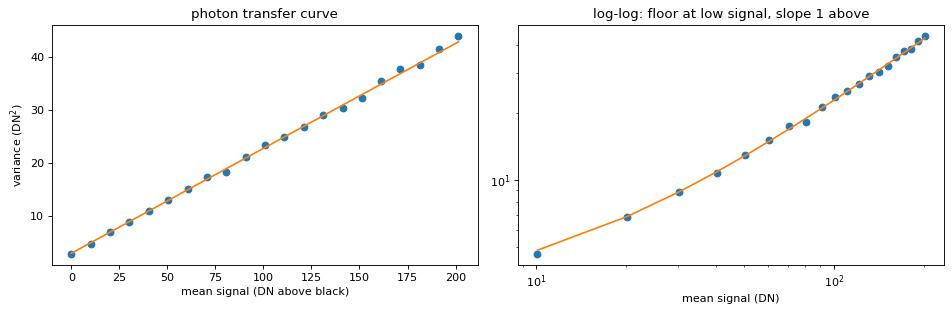

gain from the slope: 0.1990 DN/e-   (sensor: 0.2016)
read noise from the intercept: 8.4 e-   (sensor: 8.0)


In [10]:
def ptc_demo(plot=True):
    p = sensor.clean_params(replace(P['dslr'], bits=12, black_level=64, full_well=20000, qe=0.5, dark_current=0.0, read_noise=8.0))
    iso = 100
    ptc = sensor.photon_transfer(p, exposure=0.02, iso=iso, values=np.linspace(0.0, 1.0, 21), shape=(64, 64))
    mean, var = ptc['mean'], ptc['var']
    ok = (mean > 0.05 * mean.max()) & (mean < 0.8 * mean.max())      # away from the floor and from the clipping
    slope, icpt = np.polyfit(mean[ok], var[ok], 1)
    read_e = np.sqrt(max(icpt - 1 / 12, 0)) / slope                    # remove quantisation (1/12 DN^2)
    if plot:
        fig, axs = plt.subplots(1, 2, figsize=(12, 4))
        axs[0].plot(mean, var, 'o'); axs[0].plot(mean, slope * mean + icpt, '-')
        axs[0].set_xlabel('mean signal (DN above black)'); axs[0].set_ylabel('variance (DN$^2$)'); axs[0].set_title('photon transfer curve')
        axs[1].loglog(mean[1:], var[1:], 'o'); axs[1].loglog(mean[1:], slope * mean[1:] + icpt, '-')
        axs[1].set_xlabel('mean signal (DN)'); axs[1].set_title('log-log: floor at low signal, slope 1 above')
        plt.tight_layout(); plt.show()
    return dict(gain=slope, read_noise_e=read_e, true_gain=p.gain(iso), true_read=p.read_noise)

r = ptc_demo()
print(f"gain from the slope: {r['gain']:.4f} DN/e-   (sensor: {r['true_gain']:.4f})")
print(f"read noise from the intercept: {r['read_noise_e']:.1f} e-   (sensor: {r['true_read']:.1f})")

The straight line recovers both the gain and the read noise of the simulated sensor, using nothing but flat-field statistics. The log-log view shows the two regimes: a flat floor where read noise dominates and a slope-1 rise where shot noise takes over.

## Interactive capture

Change the exposure time, the ISO and the sensor and watch brightness, grain and clipping. The title reports the electrons that scene white collects and the formula's SNR for a mid-grey pixel.

In [11]:
import ipywidgets as W
from IPython.display import display

_scene_small = scenes.load('astronaut', 128)

def capture_view(sensor_name='dslr', log2_exposure=-6.0, iso=800, flux=1e5):
    p = P[sensor_name]
    t = 2.0 ** log2_exposure
    dn, meta = sensor.capture(_scene_small, t, iso, p, flux_at_white=flux, seed=0)
    lin = sensor.normalize(dn, meta)
    e_white = flux * p.qe * t
    snr = sensor.snr_theory(0.18 * flux, p.qe, t, p.dark_current, p.read_noise)
    clipped = 100 * np.mean(lin >= 0.999)
    plt.figure(figsize=(5, 5)); plt.imshow(srgb(lin)); plt.axis('off')
    plt.title(f't = {t:.4f} s, ISO {iso}: white = {e_white:.0f} e- (well {p.full_well:.0f}), grey SNR {snr:.1f}\n{clipped:.1f} % clipped', fontsize=9)
    plt.tight_layout(); plt.show()

W.interact(capture_view, sensor_name=list(P), log2_exposure=W.FloatSlider(min=-10, max=0, step=0.5, value=-6, description='log2 t'),
           iso=W.SelectionSlider(options=[100, 200, 400, 800, 1600, 3200, 6400, 12800], value=800), flux=W.fixed(1e5));

interactive(children=(Dropdown(description='sensor_name', index=2, options=('retiga_4000r', 'aptina_mt9p031', …

## Try it

1. Pick the `phone` preset in the widget above and move the exposure until the image is well exposed at ISO 100. How long is that, compared with the DSLR? The full-well capacity explains most of it.
2. Add a fourth sensor of your own to `snr_curves` (`replace(P['dslr'], read_noise=1.0)`) and find at which photon flux the read noise stops mattering.
3. In `averaging_demo`, replace `clean_params(P['phone'])` by `P['phone']` (with its fixed pattern) and check whether the $\sqrt{M}$ law still holds for the flat field. What does the average converge to?

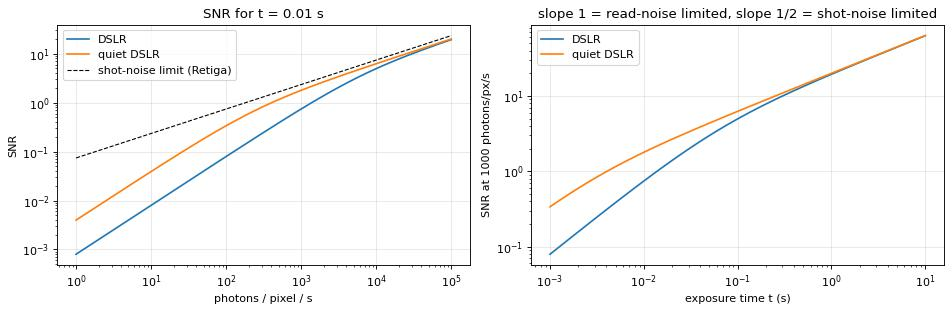

1 frames: spatial std of the average = 0.0114
4 frames: spatial std of the average = 0.0062
16 frames: spatial std of the average = 0.0039
32 frames: spatial std of the average = 0.0034


In [12]:
# Exercise 2: a quieter sensor. Edit read_noise and compare the curves.
mine = replace(P['dslr'], read_noise=1.0, name='quiet DSLR')
_ = snr_curves([P['dslr'], mine], t=0.01)

# Exercise 3: how does the std of the averaged flat field behave when PRNU is left on?
p = replace(P['phone'], prnu=0.02)
flat = np.full((64, 64), 0.3)
meta = dict(black_level=p.black_level, white_level=p.white_level)
fr = [sensor.normalize(sensor.capture(flat, 0.01, 400, p, seed=k)[0], meta, clip=False) for k in range(32)]
for M in (1, 4, 16, 32):
    print(M, 'frames: spatial std of the average = %.4f' % sensor.average_frames(fr[:M]).std())